Fetching TAT-QA dataset from GitHub...
Successfully loaded 278 financial reports into memory.


/tmp/ipykernel_473/3657900340.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_eda, x='answer_type', palette='viridis')
/tmp/ipykernel_473/3657900340.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_eda, x='evidence_source', palette='magma')
/tmp/ipykernel_473/3657900340.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_eda_filtered_scales, x='scale', palette='cubehelix')


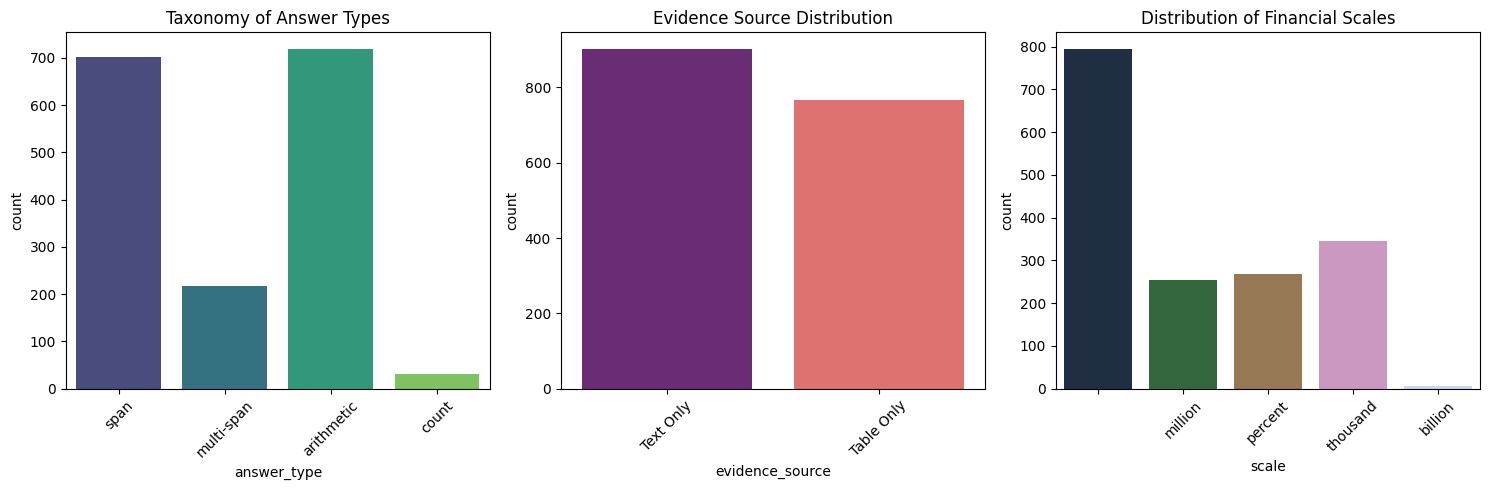


--- EDA Taxonomy Summary ---
evidence_source
Text Only     901
Table Only    767
Name: count, dtype: int64


In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# 1. Fetch the TAT-QA Dataset directly from the official GitHub repository
url = "https://raw.githubusercontent.com/NExTplusplus/TAT-QA/master/dataset_raw/tatqa_dataset_dev.json"
print("Fetching TAT-QA dataset from GitHub...")
response = requests.get(url)

if response.status_code == 200:
    tatqa_raw = response.json()
    print(f"Successfully loaded {len(tatqa_raw)} financial reports into memory.")
else:
    print(f"Failed to fetch data. HTTP Status code: {response.status_code}")
    tatqa_raw = []

# 2. Flatten the schema to extract questions and their metadata
questions_list = []
if tatqa_raw:
    for report in tatqa_raw:
        table = report.get('table', {})
        paragraphs = report.get('paragraphs', [])

        for q in report.get('questions', []):
            # Categorize reasoning type based on exact derivation or answer type
            reasoning_type = q.get('answer_type', 'unknown')
            if q.get('derivation'):
                reasoning_type = 'arithmetic/multi-step'

            # Determine if evidence is Table, Text, or Both
            rel_paragraphs = q.get('rel_paragraphs', [])
            rel_table = q.get('rel_table_regions', [])
            evidence_source = 'Table Only'
            if rel_paragraphs and not rel_table:
                evidence_source = 'Text Only'
            elif rel_paragraphs and rel_table:
                evidence_source = 'Table & Text (Hybrid)'

            questions_list.append({
                'qid': q.get('uid'),
                'question': q.get('question'),
                'answer': q.get('answer'),
                'answer_type': q.get('answer_type'), # span, multi-span, count, arithmetic
                'reasoning_category': reasoning_type,
                'scale': q.get('scale', 'None'),
                'evidence_source': evidence_source,
                'derivation': q.get('derivation', '')
            })

    df_eda = pd.DataFrame(questions_list)

    # 3. Exploratory Data Analysis (EDA) & Taxonomy Generation
    plt.figure(figsize=(15, 5))

    # Plot 1: Answer Types Taxonomy
    plt.subplot(1, 3, 1)
    sns.countplot(data=df_eda, x='answer_type', palette='viridis')
    plt.title('Taxonomy of Answer Types')
    plt.xticks(rotation=45)

    # Plot 2: Evidence Source (Crucial for Hybrid RAG)
    plt.subplot(1, 3, 2)
    sns.countplot(data=df_eda, x='evidence_source', palette='magma')
    plt.title('Evidence Source Distribution')
    plt.xticks(rotation=45)

    # Plot 3: Scale/Units Taxonomy (Crucial for Financial Tooling)
    # Filter out 'None' from the 'scale' column before plotting
    df_eda_filtered_scales = df_eda[df_eda['scale'] != 'None']
    plt.subplot(1, 3, 3)
    sns.countplot(data=df_eda_filtered_scales, x='scale', palette='cubehelix')
    plt.title('Distribution of Financial Scales')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

    print("\n--- EDA Taxonomy Summary ---")
    print(df_eda['evidence_source'].value_counts())

In [ ]:
import uuid
import json
import pandas as pd

cleaned_rag_dataset = []

# Checking if tatqa_raw was successfully loaded in the previous step
if 'tatqa_raw' in locals() and tatqa_raw:
    for report in tatqa_raw:
        table = report.get('table', {}).get('table', [])
        paragraphs = {p['order']: p['text'] for p in report.get('paragraphs', [])}

        for q in report.get('questions', []):
            qid = q.get('uid', str(uuid.uuid4()))

            # 1. Preserve Relevant Evidence (Text)
            rel_para_indices = q.get('rel_paragraphs', [])
            relevant_text = [paragraphs[i] for i in rel_para_indices if i in paragraphs]

            # 2. Preserve Relevant Evidence (Table)
            rel_table_regions = q.get('rel_table_regions', [])
            relevant_table_rows = []
            if table:
                relevant_table_rows.append(table[0]) # Always preserve header
                for region in rel_table_regions:
                    row_idx = region[0]
                    if row_idx < len(table) and row_idx != 0:
                        if table[row_idx] not in relevant_table_rows:
                            relevant_table_rows.append(table[row_idx])

            # 3. Normalize Units (Scale mapping for deterministic computation)
            scale_str = q.get('scale', '').lower()
            scale_multiplier = 1
            if scale_str == 'thousand':
                scale_multiplier = 1000
            elif scale_str == 'million':
                scale_multiplier = 1_000_000
            elif scale_str == 'billion':
                scale_multiplier = 1_000_000_000
            elif scale_str == 'percent':
                scale_multiplier = 0.01

            # 4. Construct Cleaned Object for Vector DB / Multi-Agent ingestion
            cleaned_entry = {
                'id': qid,
                'metadata': {
                    'scale_string': scale_str,
                    'scale_multiplier': scale_multiplier,
                    'answer_type': q.get('answer_type'),
                    'report_context': report.get('table', {}).get('uid', 'unknown_report')
                },
                'question': q.get('question'),
                'evidence': {
                    'text': " | ".join(relevant_text),
                    'table': relevant_table_rows
                },
                'ground_truth': {
                    'answer': q.get('answer'),
                    'derivation': q.get('derivation', 'No derivation provided')
                }
            }
            cleaned_rag_dataset.append(cleaned_entry)

    df_cleaned = pd.DataFrame(cleaned_rag_dataset)

    # Export to JSON in the Colab environment
    output_filename = 'cleaned_tatqa_rag_data.json'
    with open(output_filename, 'w', encoding='utf-8') as f:
        json.dump(cleaned_rag_dataset, f, indent=4)

    print(f"\nSuccessfully cleaned and processed {len(cleaned_rag_dataset)} questions.")
    print(f"Data saved to {output_filename} in your Colab files. Ready for embedding and RAG indexing!")

    print("\n--- Sample Cleaned Entry ---")
    print(json.dumps(cleaned_rag_dataset[0], indent=2))
else:
    print("Error: 'tatqa_raw' not found. Please run the Task 1 code block first.")


Successfully cleaned and processed 1668 questions.
Data saved to cleaned_tatqa_rag_data.json in your Colab files. Ready for embedding and RAG indexing!

--- Sample Cleaned Entry ---
{
  "id": "23801627-ff77-4597-8d24-1c99e2452082",
  "metadata": {
    "scale_string": "",
    "scale_multiplier": 1,
    "answer_type": "span",
    "report_context": "3ffd9053-a45d-491c-957a-1b2fa0af0570"
  },
  "question": "What is the company paid on a cost-plus type contract?",
  "evidence": {
    "text": "",
    "table": [
      [
        "",
        "",
        "Years Ended September 30,",
        ""
      ]
    ]
  },
  "ground_truth": {
    "answer": [
      "our allowable incurred costs plus a profit which can be fixed or variable depending on the contract\u2019s fee arrangement up to predetermined funding levels determined by the customer"
    ],
    "derivation": ""
  }
}


In [ ]:
# 1. Install the required package (if you haven't already)
# !pip install ydata-profiling

import json
import pandas as pd
import requests
from ydata_profiling import ProfileReport
import IPython

# 2. Fetch the TAT-QA Dataset directly from GitHub
url = "https://raw.githubusercontent.com/NExTplusplus/TAT-QA/master/dataset_raw/tatqa_dataset_dev.json"
print("Fetching TAT-QA dataset from GitHub...")
response = requests.get(url)

if response.status_code == 200:
    tatqa_raw = response.json()
    print(f"Successfully loaded {len(tatqa_raw)} financial reports into memory.")
else:
    print(f"Failed to fetch data. HTTP Status code: {response.status_code}")
    tatqa_raw = []

# 3. Flatten and Enrich Schema for a Comprehensive EDA
questions_list = []
if tatqa_raw:
    for report in tatqa_raw:
        table_data = report.get('table', {}).get('table', [])
        paragraphs = report.get('paragraphs', [])

        # Calculate context metrics
        num_paragraphs = len(paragraphs)
        table_rows = len(table_data)
        table_cols = len(table_data[0]) if table_rows > 0 else 0

        for q in report.get('questions', []):
            reasoning_type = q.get('answer_type', 'unknown')
            if q.get('derivation'):
                reasoning_type = 'arithmetic/multi-step'

            rel_paragraphs = q.get('rel_paragraphs', [])
            rel_table = q.get('rel_table_regions', [])

            if rel_paragraphs and not rel_table:
                evidence_source = 'Text Only'
            elif rel_table and not rel_paragraphs:
                evidence_source = 'Table Only'
            elif rel_paragraphs and rel_table:
                evidence_source = 'Table & Text (Hybrid)'
            else:
                evidence_source = 'Unknown'

            question_text = q.get('question', '')

            questions_list.append({
                'qid': q.get('uid'),
                'answer_type': q.get('answer_type'),
                'reasoning_category': reasoning_type,
                'scale': q.get('scale', 'None').lower(),
                'evidence_source': evidence_source,
                'question_word_count': len(question_text.split()),
                'has_derivation': bool(q.get('derivation')),
                'context_num_paragraphs': num_paragraphs,
                'context_table_rows': table_rows,
                'context_table_cols': table_cols
            })

    # 4. Create DataFrame
    df_eda = pd.DataFrame(questions_list)
    print("\nDataFrame created successfully. Generating Comprehensive EDA Document...")

    # 5. Generate Comprehensive EDA HTML Document (Removed dark_mode)
    profile = ProfileReport(
        df_eda,
        title="Finance AI - TAT-QA Comprehensive EDA Report",
        explorative=True
    )

    # Save the report as an HTML file in the Colab environment
    output_html_file = "TAT_QA_Comprehensive_EDA.html"
    profile.to_file(output_html_file)

    print(f"\n✅ Comprehensive EDA Document generated: '{output_html_file}'")

    # 6. Display the report directly inside the Colab Notebook
    display(IPython.display.HTML(filename=output_html_file))

Fetching TAT-QA dataset from GitHub...
Successfully loaded 278 financial reports into memory.

DataFrame created successfully. Generating Comprehensive EDA Document...


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 10/10 [00:00<00:00, 132731.14it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]


✅ Comprehensive EDA Document generated: 'TAT_QA_Comprehensive_EDA.html'


In [ ]:
import uuid
import json
import pandas as pd
import re
import ast
import operator
import seaborn as sns
import requests

# 1. Fetch the TAT-QA Dataset directly from the official GitHub repository
url = "https://raw.githubusercontent.com/NExTplusplus/TAT-QA/master/dataset_raw/tatqa_dataset_dev.json"
print("Fetching TAT-QA dataset from GitHub...")
response = requests.get(url)

if response.status_code == 200:
    tatqa_raw = response.json()
    print(f"Successfully loaded {len(tatqa_raw)} financial reports into memory.")
else:
    print(f"Failed to fetch data. HTTP Status code: {response.status_code}")
    tatqa_raw = []

# --- NEW: 1. Deep Text Preprocessing ---
def clean_text(text):
    """Strips latent HTML, newlines, tabs, and normalizes whitespace."""
    if not isinstance(text, str):
        text = str(text)
    text = re.sub(r'<[^>]+>', '', text)  # Strip HTML artifacts
    text = re.sub(r'[\n\t\r]', ' ', text)  # Remove newlines and tabs
    text = re.sub(r'\s+', ' ', text).strip()  # Normalize multiple spaces
    return text

# --- NEW: 2. Table Normalization ---
def clean_table(table_rows):
    """Flattens table text and normalizes empty/missing cells."""
    cleaned_table = []
    for row in table_rows:
        cleaned_row = []
        for cell in row:
            val = clean_text(cell)
            # Standardize missing/empty values for the model
            if val in ['', '-', '—', 'NaN', 'null', 'N/A']:
                val = '[EMPTY]'
            cleaned_row.append(val)
        cleaned_table.append(cleaned_row)
    return cleaned_table

# --- NEW: 3. Derivation Verification ---
def verify_derivation(derivation_str, answer, scale_multiplier):
    """Attempts to evaluate the derivation math to flag broken reasoning paths."""
    if not derivation_str:
        return "No derivation"

    try:
        # Strip out commas and the equals sign if present
        clean_expr = derivation_str.split('=')[0].replace(',', '').strip()
        # Safely evaluate the mathematical expression
        calculated = eval(clean_expr) * scale_multiplier

        # Check if calculated result roughly matches the answer (handling lists/floats)
        if isinstance(answer, list) and len(answer) > 0:
            target = float(str(answer[0]).replace(',', ''))
            # Tolerance check for floating point math
            if abs(calculated - target) < 0.01:
                return "Verified"
        return "Mismatch"
    except Exception:
        return "Unparseable"

# --- Main Processing Loop ---
cleaned_rag_dataset = []

if 'tatqa_raw' in locals() and tatqa_raw:
    for report in tatqa_raw:
        table = report.get('table', {}).get('table', [])
        paragraphs = {p['order']: p['text'] for p in report.get('paragraphs', [])}

        for q in report.get('questions', []):
            qid = q.get('uid', str(uuid.uuid4()))
            answer = q.get('answer')
            derivation = q.get('derivation', '')

            # Calculate Scale Multiplier (from previous code)
            scale_str = q.get('scale', '').lower()
            scale_multiplier = 1
            if scale_str == 'thousand': scale_multiplier = 1000
            elif scale_str == 'million': scale_multiplier = 1_000_000
            elif scale_str == 'billion': scale_multiplier = 1_000_000_000
            elif scale_str == 'percent': scale_multiplier = 0.01

            # 1. Apply Text Preprocessing to Paragraphs
            rel_para_indices = q.get('rel_paragraphs', [])
            relevant_text = [clean_text(paragraphs[i]) for i in rel_para_indices if i in paragraphs]

            # 2. Apply Table Normalization to Matrix
            rel_table_regions = q.get('rel_table_regions', [])
            relevant_table_rows = []
            if table:
                relevant_table_rows.append(table[0]) # Always preserve header
                for region in rel_table_regions:
                    row_idx = region[0]
                    if row_idx < len(table) and row_idx != 0:
                        if table[row_idx] not in relevant_table_rows:
                            relevant_table_rows.append(table[row_idx])

            # Clean the extracted table rows
            relevant_table_rows = clean_table(relevant_table_rows)

            # 3. Apply Derivation Verification
            verification_status = verify_derivation(derivation, answer, scale_multiplier)

            # Construct Fully Cleaned Object
            cleaned_entry = {
                'id': qid,
                'metadata': {
                    'scale_string': scale_str,
                    'scale_multiplier': scale_multiplier,
                    'answer_type': q.get('answer_type'),
                    'derivation_status': verification_status
                },
                'question': clean_text(q.get('question')),
                'evidence': {
                    'text': " | ".join(relevant_text),
                    'table': relevant_table_rows
                },
                'ground_truth': {
                    'answer': answer,
                    'derivation': derivation
                }
            }
            cleaned_rag_dataset.append(cleaned_entry)

    df_cleaned = pd.DataFrame(cleaned_rag_dataset)

    output_filename = 'fully_cleaned_tatqa_rag_data.json'
    with open(output_filename, 'w', encoding='utf-8') as f:
        json.dump(cleaned_rag_dataset, f, indent=4)

    print(f"Successfully cleaned and processed {len(cleaned_rag_dataset)} questions.")
    print(f"Derivation status breakdown:\n{df_cleaned['metadata'].apply(lambda x: x['derivation_status']).value_counts()}")
else:
    print("Error: 'tatqa_raw' not found. Please run the data fetch block first.")

Fetching TAT-QA dataset from GitHub...
Successfully loaded 278 financial reports into memory.
Successfully cleaned and processed 1668 questions.
Derivation status breakdown:
metadata
No derivation    834
Mismatch         690
Unparseable      144
Name: count, dtype: int64
